# Dataset analysis

Before training the models, we want a clear picture of the data available for each property. This notebook records the cleaning decisions and the distribution of the selected target.

For **Tg**, we examine the three cohorts used by the main benchmark: Bicerano, PolyInfo, and the Bicerano subset with complete MD descriptors. For **other targets**, we use just one cleaned cohort from Bicerano, PolyInfo, or Extended. Those properties are intended for experiments with structural descriptors only, not for the full comparison with MD, ChemBERTa, or GNNs.

Change `TARGET` at the beginning and rerun the notebook for each property. `datasets.py` handles the cleaning, while `RunLogger` saves the tables and figures. This notebook does not train models or change the MongoDB data.

## 1. Setup and data sources

The data come from the `biceranoPolymers`, `polyInfo_kaggle`, and `extendedPolymers` collections in the `PolymerPrediction` MongoDB database. The selected property is read from the `properties` field. The PolyInfo and Extended importers convert Tg from Celsius to kelvin before inserting the data into MongoDB. Units for the other properties should be checked against their original sources.

The MD subset is only needed for the Tg benchmark. It contains Bicerano samples with finite values for all required bulk and single-chain descriptors in the four files under `data/md_features/`.

Run this notebook from inside the repository, with the project environment and `MONGO_URI` available in `.env`. Each run is saved under `runs/dataset_analysis/`.

In [52]:
import os
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display
from pymongo import MongoClient
from scipy.stats import wasserstein_distance

# Choose one property and rerun the notebook for a separate analysis.
TARGET = "Tg"  # Tg, density, Tc, glass_cte, rubber_cte
OTHER_PROPERTY_SOURCE = "bicerano"  # Used only for non-Tg targets: bicerano, extended. 
# For Tg, analyze Bicerano and PolyInfo together, including the MD subset.
FULL_BENCHMARK = TARGET == "Tg"
PROPERTY_UNITS = {
    "Tg": "K", "density": "g/cm³", "Tc": "unit not verified",
    "glass_cte": "10⁻⁶ K⁻¹", "rubber_cte": "10⁻⁶ K⁻¹",
}
PROPERTY_LABELS = {
    "Tg": "Glass transition temperature, Tg",
    "density": "Density",
    "Tc": "Tc",
    "glass_cte": "Glass CTE",
    "rubber_cte": "Rubber CTE",
}
UNIT = PROPERTY_UNITS.get(TARGET, "unit not verified")
if TARGET == "density" and OTHER_PROPERTY_SOURCE == "extended" and not FULL_BENCHMARK:
    UNIT = "unit not verified"  # The Extended wrapper does not document density units.
LABEL = f"{PROPERTY_LABELS.get(TARGET, TARGET)} ({UNIT})"

# Locate the repository.
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src/final_comparison/datasets.py").is_file() and (p / "runlog.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the polymer_prediction repository")

sys.path.insert(0, str(ROOT))
load_dotenv(ROOT / ".env")
if not os.getenv("MONGO_URI"):
    raise EnvironmentError("MONGO_URI is missing from the environment or .env")

from runlog import RunLogger
from src.final_comparison.datasets import DB_NAME, COLLECTIONS, load_cohort

if not FULL_BENCHMARK and OTHER_PROPERTY_SOURCE not in COLLECTIONS:
    raise ValueError(f"Unknown source: {OTHER_PROPERTY_SOURCE}")
SOURCES = ("bicerano", "polyinfo") if FULL_BENCHMARK else (OTHER_PROPERTY_SOURCE,)
SOURCE_LABELS = {"bicerano": "Bicerano", "polyinfo": "PolyInfo", "extended": "Extended"}

MD_DIR = ROOT / "data" / "md_features"
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False})

# Keep exploratory logs separate from the historical model runs.
log = RunLogger(
    config={"db": DB_NAME, "collection": "+".join(COLLECTIONS[source] for source in SOURCES),
            "target": TARGET, "use_md": False, "analysis_type": "dataset_eda",
            "benchmark_scope": "three_cohorts" if FULL_BENCHMARK else "structural_only"},
    tag=f"eda_{TARGET}_{datetime.now():%H%M%S}",
    root=ROOT / "runs" / "dataset_analysis",
)
log.note("Dataset exploration only. No model is trained; model-specific text in the legacy report template does not apply.")
print("Repository:", ROOT)
print("Target:", TARGET)
print("Run output:", log.dir)

[runlog] C:\Users\Vale\OneDrive\Desktop\uni\tirocinio\polymer_prediction\runs\dataset_analysis\11-19_1943_biceranoPolymers-polyInfo_kaggle_nomd_eda_Tg_194336
Repository: C:\Users\Vale\OneDrive\Desktop\uni\tirocinio\polymer_prediction
Target: Tg
Run output: C:\Users\Vale\OneDrive\Desktop\uni\tirocinio\polymer_prediction\runs\dataset_analysis\11-19_1943_biceranoPolymers-polyInfo_kaggle_nomd_eda_Tg_194336


## 2. Cleaned cohorts

Each run keeps samples with a valid SMILES and a finite value for the selected target, applying the same duplicate rules as the benchmark.

For Tg, we load both collections and the MD subset. For the other properties, we load **one source and one target-specific cohort**. We do not require MD descriptors or use the other models for these exploratory targets.

In [53]:
with MongoClient(os.environ["MONGO_URI"]) as mongo:
    loaded = {
        source: load_cohort(source, target=TARGET, client=mongo)
        for source in SOURCES
    }
    if FULL_BENCHMARK:
        md_common, excluded_md = load_cohort(
            "bicerano", target=TARGET, md_dir=MD_DIR, client=mongo
        )

source_cohorts = {SOURCE_LABELS[source]: data[0] for source, data in loaded.items()}
source_exclusions = {SOURCE_LABELS[source]: data[1] for source, data in loaded.items()}
cohorts = dict(source_cohorts)

if FULL_BENCHMARK:
    bicerano = source_cohorts["Bicerano"]
    md_ids = set(md_common.sample_id)
    without_md = bicerano.loc[~bicerano.sample_id.isin(md_ids)].copy()
    assert md_ids.issubset(set(bicerano.sample_id))
    assert len(md_common) + len(without_md) == len(bicerano)
    cohorts["MD common"] = md_common

assert all(df.sample_id.is_unique and df.canonical_smiles.is_unique for df in cohorts.values())
assert all(np.isfinite(df.target_value.to_numpy(float)).all() for df in cohorts.values())

cohort_sizes = pd.DataFrame({
    "Cohort": list(cohorts),
    "Samples": [len(frame) for frame in cohorts.values()],
})
display(cohort_sizes)
log.table("cohort_sizes", cohort_sizes, index=False)
log.result("cohort_sizes", {name: len(frame) for name, frame in cohorts.items()})
log.dataset(
    db=DB_NAME,
    collection=" + ".join(COLLECTIONS[source] for source in SOURCES),
    n_docs=sum(len(kept) + len(excluded) for kept, excluded in loaded.values()),
    n_polymers=sum(len(frame) for frame in source_cohorts.values()),
)

if not any(len(frame) for frame in source_cohorts.values()):
    print(f"No usable {TARGET} observations were found in the selected source.")

,Cohort,Samples
0,Bicerano,312
1,PolyInfo,7077
2,MD common,135


### Cleaning report

The loader keeps one reason for every excluded sample. We can therefore tell how many observations were lost because of invalid SMILES, missing or conflicting target values, or duplicates.

Cleaning is target-specific: a polymer excluded from the Tg run may still be usable for another property.

In [54]:
audit = pd.DataFrame([
    {
        "Dataset": name,
        "Raw rows": len(cleaned) + len(source_exclusions[name]),
        "Excluded": len(source_exclusions[name]),
        "Retained": len(cleaned),
        "Retained (%)": 100 * len(cleaned) / (len(cleaned) + len(source_exclusions[name]))
        if len(cleaned) + len(source_exclusions[name]) else np.nan,
    }
    for name, cleaned in source_cohorts.items()
])
display(audit.round(1))

exclusion_reasons = (
    pd.concat([
        excluded.assign(dataset=name)
        for name, excluded in source_exclusions.items()
    ], ignore_index=True)
    .groupby(["dataset", "decision"]).size().rename("Rows").reset_index()
)
display(exclusion_reasons)
log.table("cleaning_audit", audit, index=False)
log.table("exclusion_reasons", exclusion_reasons, index=False)

if FULL_BENCHMARK:
    md_unavailable = excluded_md.loc[
        excluded_md.decision.eq("exclude_md_unavailable_or_nonfinite")
    ]
    assert len(md_unavailable) == len(without_md)
    print(f"Bicerano samples without complete MD data: {len(md_unavailable)}")
    log.result("cleaning", {"md_unavailable": len(md_unavailable)})

,Dataset,Raw rows,Excluded,Retained,Retained (%)
0,Bicerano,315,3,312,99.0
1,PolyInfo,7284,207,7077,97.2


,dataset,decision,Rows
0,Bicerano,exclude_conflicting_Tg_group,2
1,Bicerano,exclude_double_bracket_smiles,1
2,PolyInfo,exclude_conflicting_Tg_group,131
3,PolyInfo,exclude_identical_Tg_duplicate,9
4,PolyInfo,exclude_rdkit_invalid,67


Bicerano samples without complete MD data: 177


## 3. Distribution of the selected property

We first look at the range and spread of the selected target. For Tg, we compare the cleaned Bicerano and PolyInfo distributions. For the other properties, we show the distribution of the single cleaned cohort.

Histograms use probability density rather than raw counts, so their scale does not depend on the number of samples.

In [55]:
target_statistics = pd.DataFrame({
    name: frame.target_value.describe(percentiles=[.05, .25, .50, .75, .95])
    for name, frame in cohorts.items() if len(frame)
}).T.rename(columns={
    "count": "n", "mean": "Mean", "std": "SD",
    "min": "Min", "5%": "P05", "25%": "P25",
    "50%": "Median", "75%": "P75", "95%": "P95", "max": "Max",
})
target_statistics.index.name = "Cohort"
if len(target_statistics):
    display(target_statistics.round(2))
    log.table("target_summary", target_statistics.reset_index(), index=False)
else:
    print(f"No valid {TARGET} values are available in these collections.")

,n,Mean,SD,Min,P05,P25,Median,P75,P95,Max
Cohort,,,,,,,,,,
Bicerano,312.0,364.96,119.40,130.00,198.10,272.75,360.00,419.25,599.45,685.00
PolyInfo,7077.0,414.73,111.81,134.15,235.15,328.15,407.15,503.15,597.15,768.15
MD common,135.0,305.10,74.92,188.00,198.40,231.00,315.00,373.00,409.60,493.00


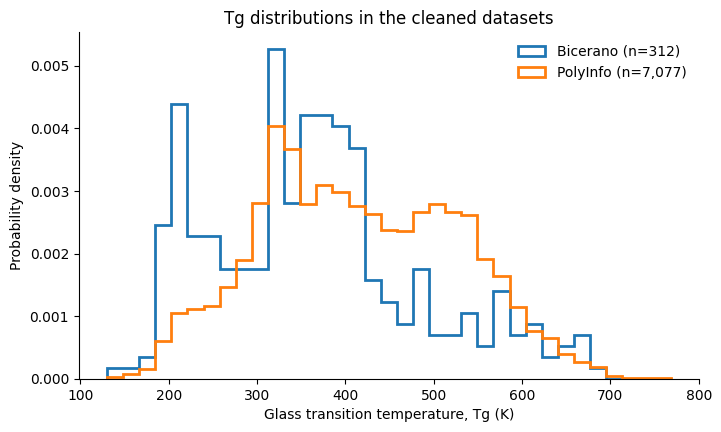

In [56]:
groups = {name: frame.target_value for name, frame in source_cohorts.items() if len(frame) >= 2}
if groups:
    all_values = np.concatenate([values.to_numpy() for values in groups.values()])
    bins = np.histogram_bin_edges(all_values, bins=35)
    fig, ax = plt.subplots()
    for name, values in groups.items():
        ax.hist(values, bins=bins, density=True, histtype="step",
                linewidth=2, label=f"{name} (n={len(values):,})")
    ax.set(title=f"{TARGET} in the cleaned cohort" if not FULL_BENCHMARK
           else f"{TARGET} distributions in the cleaned datasets",
           xlabel=LABEL, ylabel="Probability density")
    ax.legend(frameon=False)
    log.figure("target_distributions", fig)
    plt.show()
else:
    print("Not enough observations to plot the selected property.")

## 4. Is the MD subset representative? (Tg only)

For the main Tg benchmark, the MD subset is selected by descriptor availability rather than random sampling. We compare its Tg distribution with that of the Bicerano samples **outside** the subset, without counting the same samples twice.

The difference in means and the Wasserstein distance are measured in kelvin. They describe how the distributions differ, not why they differ.

This section is skipped for other targets, since their planned experiments use structural descriptors only.

In [57]:
if FULL_BENCHMARK:
    selected = md_common.target_value
    remaining = without_md.target_value

    if len(selected) and len(remaining):
        md_comparison = pd.DataFrame([{
            "MD samples": len(md_common),
            "Other Bicerano samples": len(without_md),
            "MD coverage (%)": 100 * len(md_common) / len(bicerano),
            "Mean with MD": selected.mean(),
            "Mean without MD": remaining.mean(),
            "Mean difference": selected.mean() - remaining.mean(),
            "Wasserstein distance": wasserstein_distance(selected, remaining),
            "Unit": UNIT,
        }])
        display(md_comparison.round(2))
        log.table("md_target_comparison", md_comparison, index=False)
    else:
        print("Cannot compare MD coverage: one group has no observations.")

,MD samples,Other Bicerano samples,MD coverage (%),Mean with MD,Mean without MD,Mean difference,Wasserstein distance,Unit
0,135,177,43.27,305.1,410.63,-105.53,107.24,K


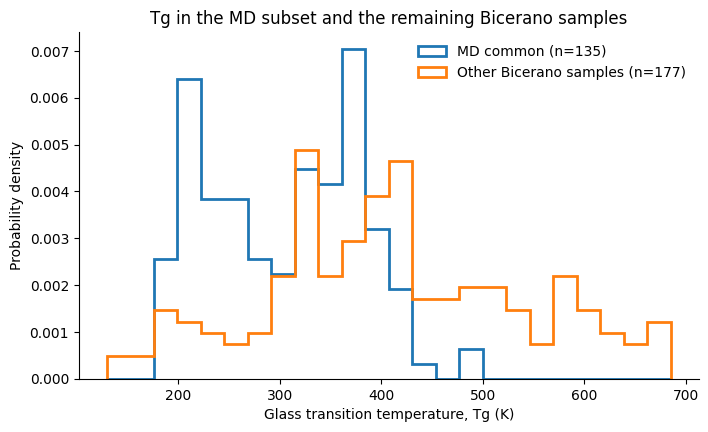

In [58]:
if FULL_BENCHMARK and len(selected) >= 2 and len(remaining) >= 2:
    bins = np.histogram_bin_edges(bicerano.target_value.to_numpy(), bins=24)
    fig, ax = plt.subplots()
    for name, values in (("MD common", selected), ("Other Bicerano samples", remaining)):
        ax.hist(values, bins=bins, density=True, histtype="step",
                linewidth=2, label=f"{name} (n={len(values)})")
    ax.set(title="Tg in the MD subset and the remaining Bicerano samples",
           xlabel=LABEL, ylabel="Probability density")
    ax.legend(frameon=False)
    log.figure("md_target_distributions", fig)
    plt.show()

### Coverage across the Tg range

For the Tg benchmark, we divide the cleaned Bicerano samples into quartiles and calculate the share with complete MD descriptors in each one. If repeated values lead to identical quartile boundaries, pandas uses fewer groups.

,quartile,parent_n,md_n,coverage_pct
0,"(129.999, 272.75]",78,54,69.2
1,"(272.75, 360.0]",80,40,50.0
2,"(360.0, 419.25]",76,37,48.7
3,"(419.25, 685.0]",78,4,5.1


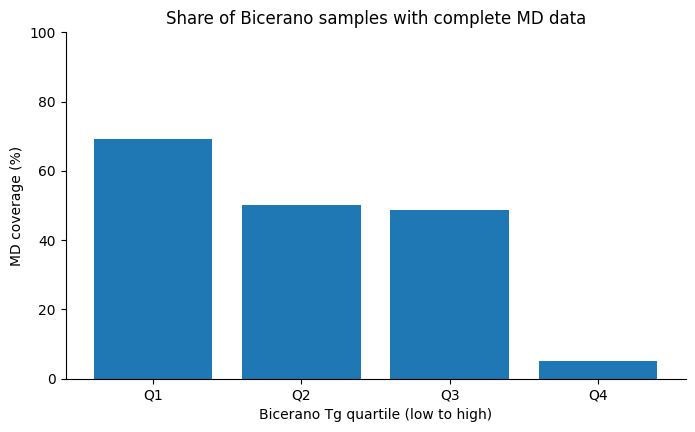

In [59]:
if FULL_BENCHMARK and len(bicerano) >= 8 and bicerano.target_value.nunique() > 1:
    quartiles = pd.qcut(bicerano.target_value, q=4, duplicates="drop")
    coverage = (
        bicerano.assign(quartile=quartiles, has_md=bicerano.sample_id.isin(md_ids))
        .groupby("quartile", observed=True)["has_md"]
        .agg(parent_n="size", md_n="sum")
    )
    if len(coverage):
        coverage["coverage_pct"] = 100 * coverage.md_n / coverage.parent_n
        display(coverage.reset_index().round(1))
        log.table("md_coverage_by_target_quartile", coverage.reset_index(), index=False)

        fig, ax = plt.subplots()
        ax.bar([f"Q{i + 1}" for i in range(len(coverage))], coverage.coverage_pct)
        ax.set(title="Share of Bicerano samples with complete MD data",
               xlabel="Bicerano Tg quartile (low to high)", ylabel="MD coverage (%)",
               ylim=(0, 100))
        log.figure("md_coverage_by_target_quartile", fig)
        plt.show()

## 5. Structural overlap between the two sources (Tg only)

For Tg, the final benchmark evaluates Bicerano and PolyInfo as separate cohorts. We check whether the same canonical repeat-unit SMILES appears in both sources. Shared structures do not necessarily mean identical measurements.

This is a descriptive check: it does not merge the datasets. For other properties, the analysis uses only the selected source, so no cross-source comparison is needed.

In [60]:
if FULL_BENCHMARK:
    overlap = source_cohorts["Bicerano"][["canonical_smiles", "target_value"]].merge(
        source_cohorts["PolyInfo"][["canonical_smiles", "target_value"]],
        on="canonical_smiles", suffixes=("_bicerano", "_polyinfo"),
        validate="one_to_one",
    )
    print(f"Shared canonical structures with Tg in both sources: {len(overlap)}")
    if len(overlap):
        overlap["Absolute difference"] = (
            overlap.target_value_bicerano - overlap.target_value_polyinfo
        ).abs()
        display(overlap[["target_value_bicerano", "target_value_polyinfo", "Absolute difference"]]
                .describe().round(2))
    log.table("cross_source_overlap", overlap, index=False)
    log.result("cross_source_overlap", {"shared_structures": len(overlap)})

Shared canonical structures with Tg in both sources: 23


,target_value_bicerano,target_value_polyinfo,Absolute difference
count,23.00,23.00,23.00
mean,246.43,249.96,7.48
std,57.89,59.40,11.99
min,188.00,187.65,0.15
25%,205.50,204.05,0.25
50%,220.00,220.15,4.15
75%,290.00,297.40,9.15
max,355.00,357.15,57.15


## 6. Save results

All tables and figures are saved with `RunLogger`. Its original `report.md` template was written for model-training runs, so the tables, figures, and `run.json` are the reliable outputs of this exploratory analysis.

In [61]:
log.result("dataset_analysis", {
    "target": TARGET,
    "unit": UNIT,
    "sources": list(SOURCES),
    "benchmark_scope": "three_cohorts" if FULL_BENCHMARK else "structural_only",
})
if not FULL_BENCHMARK:
    log.note(f"Only {SOURCE_LABELS[OTHER_PROPERTY_SOURCE]} is used for {TARGET}. No MD or GNN comparison is planned.")
if UNIT == "unit not verified":
    log.note(f"Units for {TARGET} have not been verified.")
output_dir = log.finish(quiet=True)
print("Exploratory results saved to:", output_dir)
print("Tables:", output_dir / "tables")
print("Figures:", output_dir / "figures")
print("Run manifest:", output_dir / "run.json")

Exploratory results saved to: C:\Users\Vale\OneDrive\Desktop\uni\tirocinio\polymer_prediction\runs\dataset_analysis\11-19_1943_biceranoPolymers-polyInfo_kaggle_nomd_eda_Tg_194336
Tables: C:\Users\Vale\OneDrive\Desktop\uni\tirocinio\polymer_prediction\runs\dataset_analysis\11-19_1943_biceranoPolymers-polyInfo_kaggle_nomd_eda_Tg_194336\tables
Figures: C:\Users\Vale\OneDrive\Desktop\uni\tirocinio\polymer_prediction\runs\dataset_analysis\11-19_1943_biceranoPolymers-polyInfo_kaggle_nomd_eda_Tg_194336\figures
Run manifest: C:\Users\Vale\OneDrive\Desktop\uni\tirocinio\polymer_prediction\runs\dataset_analysis\11-19_1943_biceranoPolymers-polyInfo_kaggle_nomd_eda_Tg_194336\run.json
